# Specification Curve (robustness to analyst choices)

**Family:** Uncertainty &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Advanced

> *Uncertainty:* Show what is not known (intervals, probabilities and possible outcomes) so readers do not over-trust a single number.

## Design purpose

Runs the same analysis under every reasonable combination of analyst choices (data window, definitions, filters, costs) and plots all the resulting estimates, sorted, with their confidence intervals. A dashboard below shows which choices produced each estimate. The reader sees whether a result is robust or hinges on a few convenient decisions, a source of uncertainty that standard errors leave out.

## When to use

- Show that a backtest, factor premium or model result does not depend on cherry-picked settings
- Find which choices drive the result (look for bands in the dashboard that line up with high or low estimates)
- Pre-empt the "garden of forking paths" criticism in research, due diligence or model validation

## Avoid when

- Including unreasonable or redundant specifications to inflate the count (define the set before looking at results)
- There are only two or three plausible specifications (a small table is clearer)
- The audience needs a single number for a decision (report the median estimate and the share of specs that agree)

## Alternatives

- Multiverse analysis (histogram of estimates plus a tile plot of choices)
- Forest plot of a few key specifications
- Sensitivity tornado chart (one choice at a time)

## Design tips

- What it fixes: reporting one specification hides how much the answer depends on analyst choices
- Sort by estimate and color by significance; the share of significant specifications is a useful headline
- Order dashboard rows by choice, and keep each choice's options adjacent, so systematic patterns show as diagonal bands
- For formal joint inference, compare the observed curve with curves from data where the effect is removed by construction (e.g. shuffled signals)

## Example

A simulated momentum strategy's Sharpe ratio, estimated over 20 years under 288 specifications: 4 lookback windows × skip-month yes/no × 2 rebalance frequencies × 3 universes × 3 transaction-cost levels × 2 winsorising rules.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from itertools import product

### Data

In [2]:
rng = np.random.default_rng(2020)
choices = {  # option -> its (simulated) effect on the Sharpe ratio
    "Lookback": {"3 m": -0.25, "6 m": 0.0, "9 m": 0.05, "12 m": 0.08},
    "Skip last month": {"No": 0.0, "Yes": 0.08},
    "Rebalance": {"Monthly": 0.0, "Quarterly": -0.05},
    "Universe": {"Large caps": -0.12, "All stocks": 0.0, "Ex-financials": 0.03},
    "Trading cost": {"0 bp": 0.0, "10 bp": -0.12, "25 bp": -0.30},
    "Winsorise": {"None": 0.0, "1%": 0.02},
}
years = 20
specs = pd.DataFrame(list(product(*[list(v) for v in choices.values()])), columns=list(choices))
specs["sharpe"] = 0.55 + sum(specs[c].map(v) for c, v in choices.items()) + rng.normal(0, 0.04, len(specs))
se = np.sqrt((1 + 0.5 * specs["sharpe"] ** 2) / years)  # standard error of an annual Sharpe ratio
specs["lo"], specs["hi"] = specs["sharpe"] - 1.96 * se, specs["sharpe"] + 1.96 * se
specs = specs.sort_values("sharpe").reset_index(drop=True)
specs.describe().round(2)

,sharpe,lo,hi
count,288.00,288.00,288.00
mean,0.37,-0.08,0.83
std,0.20,0.19,0.22
min,-0.25,-0.70,0.19
25%,0.24,-0.21,0.68
50%,0.39,-0.07,0.84
75%,0.53,0.06,1.00
max,0.75,0.26,1.25


### Plot

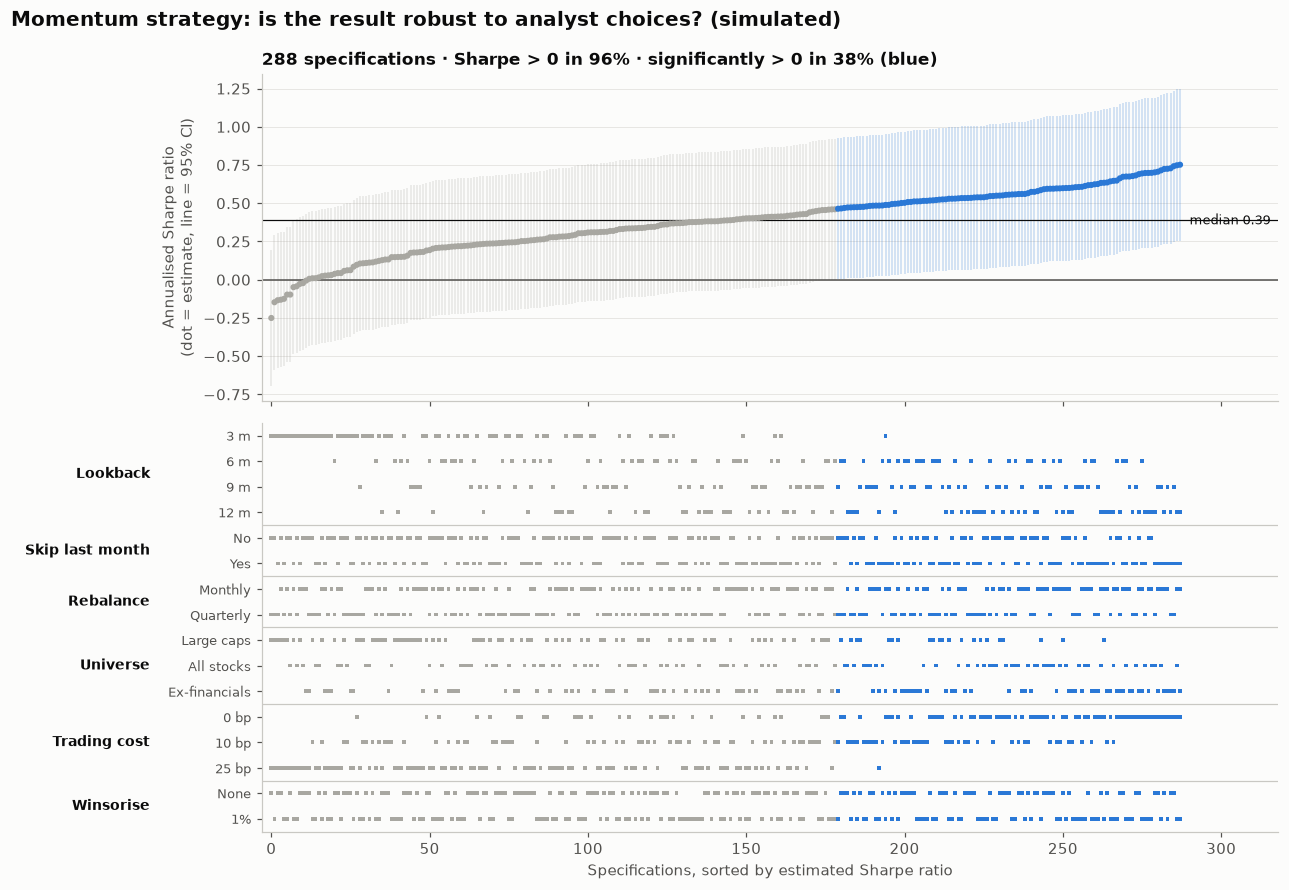

In [3]:
sig_pos, sig_neg = specs["lo"] > 0, specs["hi"] < 0
col = np.where(sig_pos, PALETTE[0], np.where(sig_neg, PALETTE[1], "#a8a7a1"))
x = np.arange(len(specs))
rows = [(c, o) for c, opts in choices.items() for o in opts]

fig, (a1, a2) = plt.subplots(2, 1, figsize=(12, 8.2), sharex=True,
                             gridspec_kw={"height_ratios": [1, 1.25], "hspace": 0.06})
a1.vlines(x, specs["lo"], specs["hi"], color=col, alpha=0.25, linewidth=1)
a1.scatter(x, specs["sharpe"], s=9, color=col, zorder=3)
a1.axhline(0, color="#52514e", linewidth=1)
med = specs["sharpe"].median()
a1.axhline(med, color="#0b0b0b", linewidth=0.8)
a1.text(len(specs) + 2, med, f"median {med:.2f}", va="center", fontsize=8.5)
a1.set_ylabel("Annualised Sharpe ratio\n(dot = estimate, line = 95% CI)")
a1.set_title(f"{len(specs)} specifications · Sharpe > 0 in {(specs['sharpe'] > 0).mean():.0%} · "
             f"significantly > 0 in {sig_pos.mean():.0%} (blue)", fontsize=11)
a1.grid(axis="x", visible=False)

for r, (c, o) in enumerate(rows):
    on = specs[c] == o
    a2.scatter(x[on], np.full(on.sum(), r), s=6, marker="s", color=col[on], linewidths=0)
bounds = np.cumsum([len(v) for v in choices.values()])[:-1] - 0.5
for b in bounds:
    a2.axhline(b, color="#c9c8c3", linewidth=0.8)
a2.set_yticks(range(len(rows)), [o for _, o in rows], fontsize=8.5)
start = 0
for c, opts in choices.items():  # choice names in the left margin
    a2.text(-0.11, start + (len(opts) - 1) / 2, c, transform=a2.get_yaxis_transform(), ha="right",
            va="center", fontsize=9, fontweight="bold")
    start += len(opts)
a2.set_ylim(len(rows) - 0.5, -0.5)
a2.set_xlim(-3, len(specs) + 30)
a2.set_xlabel("Specifications, sorted by estimated Sharpe ratio")
a2.grid(False)

fig.suptitle("Momentum strategy: is the result robust to analyst choices? (simulated)", x=0.01, ha="left",
             fontweight="bold", fontsize=13)
fig.subplots_adjust(left=0.2, right=0.97, top=0.91, bottom=0.07)
plt.show()

## How to read it

Each dot is the Sharpe ratio under one specification, sorted from lowest to highest, and its line is the 95% CI. Blue dots are significantly above zero, gray ones are not. The dashboard below shows that the low end of the curve is dominated by the 3-month lookback and the 25 bp cost assumption, while results above the median need low costs. The strategy is robustly positive only when trading costs stay low.

## Reference

This method comes from the research literature:

- Simonsohn, U., Simmons, J. P. & Nelson, L. D. (2020). Specification curve analysis. Nature Human Behaviour 4, 1208–1214. <https://doi.org/10.1038/s41562-020-0912-z>

---
Standalone script: [`specification_curve.py`](specification_curve.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)